# 面向肿瘤疫苗的二元聚氨基酸佐剂与递送载体分层筛选

**全球大学生生命科学挑战赛｜计算方法与结果复现**

**研究目标：** 面向肿瘤疫苗递送及免疫增强需求，针对**二元聚氨基酸材料**建立文献知识与理化特征相结合的分层筛选流程，识别值得优先开展材料合成、组装表征及生物学验证的候选体系。研究目标是从材料候选空间中进行合理筛选，**不是预先限定某一个固定结构式并验证其优越性**。

**研究思路：** 首先根据公开文献中与递送、免疫响应及材料安全性有关的证据比较阳离子功能模块和手性；随后在第一阶段筛选结果的基础上，对另一功能嵌段的氨基酸候选进行化学机制分域，选择可追溯的单残基理化指标，实施域内评分、排序和稳健性分析。最终提出三组优先实验验证的二元聚氨基酸候选材料。

**计算流程：**

1. **Stage 1：阳离子功能模块筛选**——文献检索策略、筛选记录、MedCPT 语义相关性排序、关键论文证据，以及阳离子氨基酸与手性选择。
2. **Stage 2：第二功能嵌段筛选**——机制分域、候选理化指标发现与映射、决策矩阵、域内排序和敏感性检验。

**数据与方法说明：** Stage 1 读取项目已保存的 Europe PMC 检索记录、MedCPT 排序结果及证据整理记录，以便复核原有文献筛选过程；不重复进行在线检索或语言模型推理。Stage 2 基于保存的单残基描述符重新执行归一化、排名、稳健性分析和绘图。文献证据整理陈述与数据库检索摘要分别标识，单残基指标用于候选优先级决策，不直接等同于长链聚氨基酸的实验性能。

## 0. 数据来源与计算环境

加载研究项目保存的检索、证据及理化特征数据；数据统计、决策分析及图表在执行过程中生成。图像统一输出至 `notebook_demo_output/`，不覆盖原始研究结果。

In [2]:
from pathlib import Path
import json, sys, textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown


def locate_project():
    cwd = Path.cwd().resolve()
    checks = [cwd, *cwd.parents, cwd / 'shengmingtiaozhansai']
    for p in checks:
        if (p / 'data/stage1/literature/query_summary.csv').exists() and (p / 'src/pipeline.py').exists():
            return p
    raise FileNotFoundError('未定位项目根目录。请把Notebook放进shengmingtiaozhansai项目根目录或notebooks子目录，再重新启动内核。')

ROOT = locate_project()
OUTPUT = ROOT / 'notebook_demo_output'
OUTPUT.mkdir(parents=True, exist_ok=True)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

for font in ['Microsoft YaHei', 'SimHei', 'Noto Sans CJK SC', 'Noto Sans CJK JP', 'PingFang SC', 'WenQuanYi Micro Hei', 'DejaVu Sans']:
    # Windows优先微软雅黑；Linux环境通常能用 Noto 字体
    import matplotlib.font_manager as fm
    if any(f.name == font for f in fm.fontManager.ttflist):
        plt.rcParams['font.sans-serif'] = [font, 'DejaVu Sans']
        break
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 115
pd.set_option('display.max_colwidth', 110)
pd.set_option('display.width', 180)

def csv(rel):
    return pd.read_csv(ROOT / rel, encoding='utf-8-sig')
def jload(rel):
    return json.loads((ROOT / rel).read_text(encoding='utf-8-sig'))
def savefig(name):
    file = OUTPUT / name
    plt.savefig(file, dpi=190, bbox_inches='tight')
    plt.show()
    print('图已保存：', file.relative_to(ROOT))

print('项目根目录：', ROOT)
print('图表输出目录：', OUTPUT)
print('基础环境：numpy、pandas、matplotlib、IPython；本次数据复算无需联网或 GPU')

项目根目录： E:\Project\shengmingtiaozhansai
图表输出目录： E:\Project\shengmingtiaozhansai\notebook_demo_output
基础环境：numpy、pandas、matplotlib、IPython；本次数据复算无需联网或 GPU


# Stage 1 · 阳离子功能模块的文献证据筛选

以赖氨酸（K）、精氨酸（R）和组氨酸（H）为候选，分别收集其在生物大分子递送、内体行为、安全性及免疫相关过程中的研究证据。文献相关性评分用于证据检索与排序，材料体系适配性及 D/L 手性选择根据所整理的研究证据另行判断。

## 1.1 文献检索策略与查询词设计

在 **Europe PMC** 中开展文献检索。检索策略包含 18 个主题（阳离子氨基酸候选 12 个、赖氨酸手性比较 6 个），扩展后形成实际执行的 42 条检索式。检索配置与查询扩展记录分别保存于 `configs/stage1/functional_block_search.json` 和 `data/stage1/literature/query_expansion_snapshot.json`。

In [3]:
query = csv('data/stage1/literature/query_summary.csv')
assert {'query_id','query_variant_id','exact_query','retrieved_count'} <= set(query.columns)
print(f'原始主题 {query.query_id.nunique()} 组；实际查询 {len(query)} 条；检索记录 {int(query.retrieved_count.sum())} 条（含重复）')
summary = query.groupby(['query_group','candidate'], dropna=False).agg(
    检索主题数=('query_id','nunique'),实际查询变体数=('query_id','size'),抓取记录数=('retrieved_count','sum')
).reset_index()
display(summary)
print('查询语法示例（原始字符串，并非重新执行的网络搜索）：')
for query_id in ['K01','K02','K03','K04','R01','H02','DK01','KD02']:
    rows = query[(query.query_id == query_id) & (query.query_variant_id == 'v0')]
    if len(rows): print(f'\n[{query_id}] {rows.iloc[0]["exact_query"]}')

原始主题 18 组；实际查询 42 条；检索记录 2518 条（含重复）


,query_group,candidate,检索主题数,实际查询变体数,抓取记录数
0,candidate,H,4,12,395
1,candidate,K,4,12,1123
2,candidate,R,4,12,846
3,lys_chirality,K,6,6,154


查询语法示例（原始字符串，并非重新执行的网络搜索）：

[K01] TITLE_ABS:(polylysine OR "poly-L-lysine" OR "lysine-based polypeptide" OR "lysine polypeptide") AND TITLE_ABS:(antigen OR protein OR vaccine OR biomacromolecule OR mRNA) AND TITLE_ABS:(delivery OR carrier OR uptake OR presentation)

[K02] TITLE_ABS:(polylysine OR "poly-L-lysine" OR "lysine-based polypeptide" OR "lysine polypeptide") AND TITLE_ABS:(intracellular OR uptake OR internalization OR endosomal OR endosome)

[K03] TITLE_ABS:(polylysine OR "poly-L-lysine" OR "lysine-based polypeptide" OR "lysine polypeptide") AND TITLE_ABS:(cytotoxicity OR toxicity OR biocompatibility OR hemolysis)

[K04] TITLE_ABS:(polylysine OR "poly-L-lysine" OR "lysine-based polypeptide" OR "lysine polypeptide") AND TITLE_ABS:(dendritic OR "antigen presentation" OR "cross-presentation" OR immune OR immunotherapy OR adjuvant OR vaccine)

[R01] TITLE_ABS:(polyarginine OR "poly-L-arginine" OR "arginine-based polypeptide" OR "arginine polypeptide") AND TITLE_ABS:(antigen OR prot

下表逐条展示检索主题、查询变体、具体检索式、对应证据维度及原始取回记录数。本阶段保留不同检索式命中的重复记录，后续统计时再区分查询—文献对与去重文献。

In [4]:
queries_view = query[['query_id','query_variant_id','query_variant_source','purpose','exact_query','retrieved_count']].copy()
queries_view.columns=['主题ID','变体','来源','证据维度','Europe PMC实际检索式','取回条数']
display(queries_view)  # 42条，滚动即可阅读

,主题ID,变体,来源,证据维度,Europe PMC实际检索式,取回条数
0,K01,v0,canonical_v1_3,Direct antigen/protein/vaccine delivery evidence,"TITLE_ABS:(polylysine OR ""poly-L-lysine"" OR ""lysine-based polypeptide"" OR ""lysine polypeptide"") AND TITLE_...",200
1,K01,v1,llm_candidate_neutral_dimension_expansion,Direct antigen/protein/vaccine delivery evidence,"TITLE_ABS:(polylysine OR poly-L-lysine OR ""lysine-based polypeptide"" OR ""lysine polypeptide"") AND TITLE_AB...",2
2,K01,v2,llm_candidate_neutral_dimension_expansion,Direct antigen/protein/vaccine delivery evidence,"TITLE_ABS:(polylysine OR poly-L-lysine OR ""lysine-based polypeptide"" OR ""lysine polypeptide"") AND TITLE_AB...",0
3,K02,v0,canonical_v1_3,Intracellular and endosomal evidence,"TITLE_ABS:(polylysine OR ""poly-L-lysine"" OR ""lysine-based polypeptide"" OR ""lysine polypeptide"") AND TITLE_...",200
4,K02,v1,llm_candidate_neutral_dimension_expansion,Intracellular and endosomal evidence,"TITLE_ABS:(polylysine OR poly-L-lysine OR ""lysine-based polypeptide"" OR ""lysine polypeptide"") AND TITLE_AB...",200
5,K02,v2,llm_candidate_neutral_dimension_expansion,Intracellular and endosomal evidence,"TITLE_ABS:(polylysine OR poly-L-lysine OR ""lysine-based polypeptide"" OR ""lysine polypeptide"") AND TITLE_AB...",0
6,K03,v0,canonical_v1_3,Safety and cytotoxicity evidence,"TITLE_ABS:(polylysine OR ""poly-L-lysine"" OR ""lysine-based polypeptide"" OR ""lysine polypeptide"") AND TITLE_...",100
7,K03,v1,llm_candidate_neutral_dimension_expansion,Safety and cytotoxicity evidence,"TITLE_ABS:(polylysine OR poly-L-lysine OR ""lysine-based polypeptide"" OR ""lysine polypeptide"") AND TITLE_AB...",100
8,K03,v2,llm_candidate_neutral_dimension_expansion,Safety and cytotoxicity evidence,"TITLE_ABS:(polylysine OR poly-L-lysine OR ""lysine-based polypeptide"" OR ""lysine polypeptide"") AND TITLE_AB...",100
9,K04,v0,canonical_v1_3,Dendritic-cell and immune-activation evidence,"TITLE_ABS:(polylysine OR ""poly-L-lysine"" OR ""lysine-based polypeptide"" OR ""lysine polypeptide"") AND TITLE_...",200


## 1.2 文献筛选流程与证据数量统计

文献处理依次包括**检索记录汇总、文献去重、语义相关性排序和高相关证据保留**。其中，“文献数”按照去重后的文献记录计数，“查询—文献对数”按照检索问题与对应论文的组合计数；同一论文可以与多个查询形成不同的证据对。

MedCPT 相关性排序采用**各检索问题内部的 top-k 保留规则**，并非依据预先指定的最终文献总数筛选。以下统计表及图像从保存记录重新计算各阶段数量。

In [5]:
retrieved = csv('data/stage1/literature/retrieved_metadata.csv')
screening = csv('data/stage1/literature/screening_all.csv')
med = csv('data/stage1/medcpt/medcpt_ranked_pairs.csv')
selected = csv('data/stage1/medcpt/rag_query_document_pairs.csv')
unique_docs = csv('data/stage1/medcpt/rag_unique_documents.csv')
contexts = csv('data/stage1/rag/contextual_evidence.csv')
manifest = jload('data/stage1/medcpt/manifest.json')

funnel = pd.DataFrame([
 ('Europe PMC实际取回',len(retrieved),'查询返回记录（含重复）'),
 ('聚合去重',len(screening),'不同文献（按项目去重键）'),
 ('MedCPT相关性排序',len(med),'查询—文献对'),
 ('每问题top-k入选',len(selected),'查询—文献对'),
 ('入选文献再去重',len(unique_docs),'不同文献'),
], columns=['处理阶段','数量','统计单位'])
assert len(med) == manifest['ranked_query_document_pairs']
assert len(selected) == manifest['selected_query_document_pairs']
assert len(unique_docs) == manifest['selected_unique_documents']
assert (len(retrieved),len(screening),len(med),len(selected),len(unique_docs)) == (2518,1584,2111,97,76)
display(funnel)
print('真实Top-k策略：',manifest['top_k'])
print('检索模型：',manifest['model_id'])

,处理阶段,数量,统计单位
0,Europe PMC实际取回,2518,查询返回记录（含重复）
1,聚合去重,1584,不同文献（按项目去重键）
2,MedCPT相关性排序,2111,查询—文献对
3,每问题top-k入选,97,查询—文献对
4,入选文献再去重,76,不同文献


真实Top-k策略： {'background': 5, 'candidate': 6, 'lys_chirality': 8, 'synthetic_feasibility': 4}
检索模型： ncbi/MedCPT-Cross-Encoder


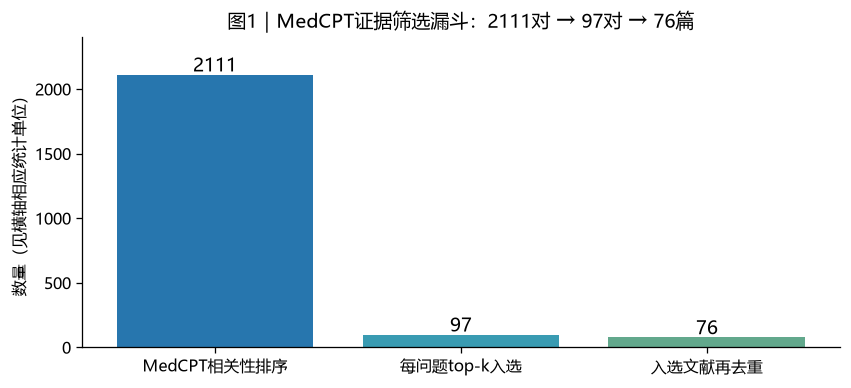

图已保存： notebook_demo_output\01_stage1_full_evidence_funnel.png


In [6]:
plot = funnel.iloc[[2,3,4]].copy()
fig, ax = plt.subplots(figsize=(8.5,3.5))
bars=ax.bar(plot['处理阶段'], plot['数量'], color=['#2776ae','#399bb2','#62a88c'])
for b,v in zip(bars,plot['数量']):ax.text(b.get_x()+b.get_width()/2,v+25,str(v),ha='center',fontsize=12)
ax.set_ylim(0,2400);ax.set_ylabel('数量（见横轴相应统计单位）')
ax.set_title('图1｜MedCPT证据筛选漏斗：2111对 → 97对 → 76篇')
ax.spines[['top','right']].set_visible(False)
savefig('01_stage1_full_evidence_funnel.png')

### 两类文献证据分支及去重统计

阳离子候选比较（K/R/H）与赖氨酸手性比较（D/L）属于两个检索分支。同一篇论文可能为多个检索问题提供证据，因此各分支的去重文献数不宜直接相加。下表分别统计各分支的证据对数、去重文献数和入选检索问题数。

,分支,入选证据对,不同文献数,入选问题数
0,candidate,65,59,11
1,lys_chirality,32,20,6


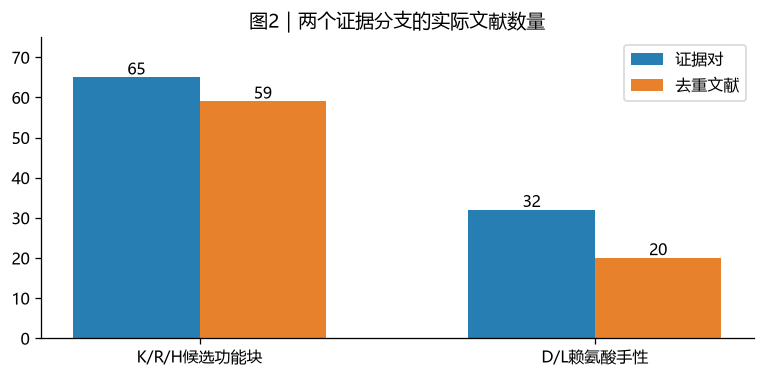

图已保存： notebook_demo_output\02_stage1_evidence_branch_breakdown.png


In [7]:
group_stats=[]
for group,g in selected.groupby('rag_query_group'):
    group_stats.append(dict(分支=group,入选证据对=len(g),不同文献数=g.dedup_key.nunique(),入选问题数=g.rag_query_id.nunique()))
branch=pd.DataFrame(group_stats).sort_values('分支')
display(branch)
assert set(branch['入选证据对']) == {65,32}
assert set(branch['不同文献数']) == {59,20}
fig, ax=plt.subplots(figsize=(8,3.4)); x=np.arange(len(branch)); w=.32
b1=ax.bar(x-w/2,branch['入选证据对'],w,label='证据对',color='#267eb3')
b2=ax.bar(x+w/2,branch['不同文献数'],w,label='去重文献',color='#e7812b')
ax.set_xticks(x,['K/R/H候选功能块','D/L赖氨酸手性'])
for bars in (b1,b2):
 for b in bars: ax.text(b.get_x()+b.get_width()/2,b.get_height()+.7,str(int(b.get_height())),ha='center')
ax.set_ylim(0,75);ax.legend();ax.set_title('图2｜两个证据分支的实际文献数量')
ax.spines[['top','right']].set_visible(False)
savefig('02_stage1_evidence_branch_breakdown.png')

## 1.3 文献语义相关性评估与 MedCPT 排序

采用 `ncbi/MedCPT-Cross-Encoder` 评估检索问题与文献摘要的语义相关程度，并在每个问题内依据得分排序、保留高相关证据。阳离子候选问题通常每题最多保留 6 对，手性问题最多保留 8 对；实际记录不足时按可用数量保留。

**相关性分数的含义：** 分数表征文献文本与检索主题的语义匹配程度，不能解释为材料的免疫增强效果、细胞毒性大小或实验性能评分。下列热图根据保存的逐项得分绘制，缺失记录以空白显示。

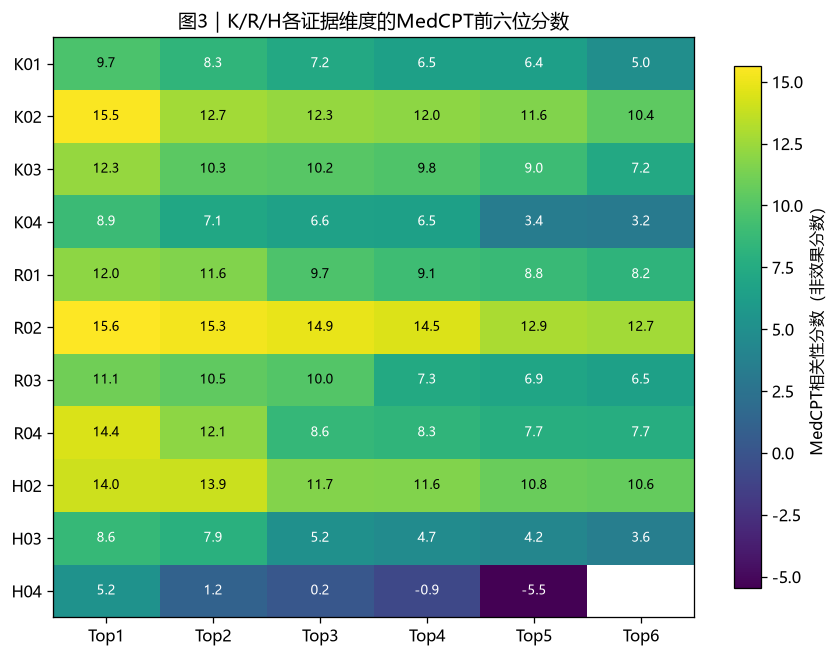

图已保存： notebook_demo_output\03_stage1_candidate_medcpt_heatmap.png


In [8]:
def medcpt_heatmap(ids, n, figure_name, title):
    sub=med[med['selected_top_k'].astype(bool) & med.rag_query_id.isin(ids)].copy()
    frame=sub.pivot_table(index='rag_query_id',columns='medcpt_rank',values='medcpt_score',aggfunc='first').reindex(ids)
    frame=frame.reindex(columns=range(1,n+1));vals=frame.to_numpy(dtype=float)
    fig,ax=plt.subplots(figsize=(9,0.45*len(ids)+1.6))
    dat=np.ma.masked_invalid(vals)
    im=ax.imshow(dat,aspect='auto',cmap='viridis')
    ax.set_yticks(range(len(ids)),ids);ax.set_xticks(range(n),[f'Top{k}' for k in range(1,n+1)])
    ax.set_title(title)
    for i in range(len(ids)):
        for j in range(n):
            if np.isfinite(vals[i,j]):
                ax.text(j,i,f'{vals[i,j]:.1f}',ha='center',va='center',fontsize=8,
                        color='black' if vals[i,j]>9 else 'white')
    fig.colorbar(im,ax=ax,label='MedCPT相关性分数（非效果分数）',shrink=.9)
    savefig(figure_name)
    return frame

heat_candidate=medcpt_heatmap(['K01','K02','K03','K04','R01','R02','R03','R04','H02','H03','H04'],6,
                              '03_stage1_candidate_medcpt_heatmap.png','图3｜K/R/H各证据维度的MedCPT前六位分数')

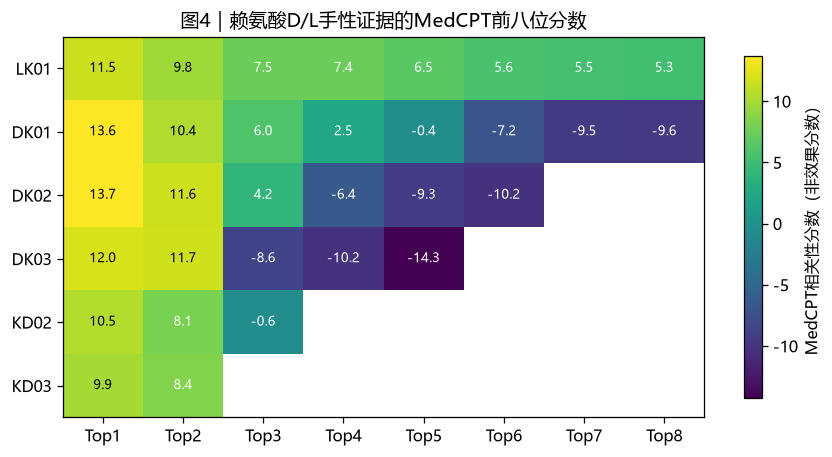

图已保存： notebook_demo_output\04_stage1_chirality_medcpt_heatmap.png


In [9]:
heat_chirality=medcpt_heatmap(['LK01','DK01','DK02','DK03','KD02','KD03'],8,
                              '04_stage1_chirality_medcpt_heatmap.png','图4｜赖氨酸D/L手性证据的MedCPT前八位分数')

## 1.4 关键文献与代表性证据对

在保存的高相关“检索问题—文献”证据对中，选取覆盖赖氨酸、精氨酸、组氨酸以及 D/L 手性比较的 20 条代表性记录。展示检索问题、文章标题、DOI、MedCPT 相关性得分及相应文献内容。为保证证据来源清晰，对两类文本作如下区分：

- **证据整理文本**：由文献处理流程形成的归纳陈述，可能包含语言模型释义，不能视为论文的逐字引文。
- **数据库检索摘要**：项目从 Europe PMC 保存的摘要字段，可用于核对研究对象、所述机制和结论适用范围。

论文证据的解释需要结合研究对象、实验设计和原始论文本身，文献相关性排序不替代证据质量评价。

In [10]:
query_to_group = selected[['rag_query_id','rag_query_group']].drop_duplicates()
evid = contexts.merge(query_to_group, on='rag_query_id', how='left', validate='many_to_one')
choice=[]
for name,cond,limit in [
 ('K',(evid.rag_query_group=='candidate')&(evid.candidate=='K'),5),
 ('R',(evid.rag_query_group=='candidate')&(evid.candidate=='R'),5),
 ('H',(evid.rag_query_group=='candidate')&(evid.candidate=='H'),4),
 ('D/L',(evid.rag_query_group=='lys_chirality'),6),
]:
    subset=evid[cond].sort_values('medcpt_score',ascending=False).head(limit)
    choice.extend(subset.evidence_id.tolist())
# 补充具有明确材料与作用机制对照的代表性论文证据
for must in ['E022','E032','E044','E093']:
    if must in set(evid.evidence_id) and must not in choice:
        record=evid.loc[evid.evidence_id==must].iloc[0]
        is_ch=record.rag_query_group=='lys_chirality'
        group_items=[x for x in choice if
          (str(evid.set_index('evidence_id').loc[x,'rag_query_group'])=='lys_chirality' if is_ch else
           str(evid.set_index('evidence_id').loc[x,'candidate'])==str(record.candidate) and
           str(evid.set_index('evidence_id').loc[x,'rag_query_group'])=='candidate')]
        if group_items:choice[choice.index(group_items[-1])]=must
choice=list(dict.fromkeys(choice))
proof=evid.set_index('evidence_id').loc[choice].reset_index()
assert len(proof)==20, f'代表性证据数量异常：{len(proof)}'
proof['证据整理陈述（非逐字原文）']=proof['supporting_text'].fillna('').astype(str).str.slice(0,230)
proof['原始检索摘要节选']=proof['abstract_text'].fillna('').astype(str).str.slice(0,290)
proof['论文DOI']=proof['doi'].fillna('无DOI记录')
pd.set_option('display.max_colwidth', 310)
display(proof[['evidence_id','rag_query_id','candidate','title','论文DOI','medcpt_score','证据整理陈述（非逐字原文）','原始检索摘要节选']].rename(columns={
 'evidence_id':'证据ID','rag_query_id':'检索问题','candidate':'氨基酸','title':'论文标题','medcpt_score':'MedCPT相关性'}))
print(f'代表性证据对：{len(proof)}；保存的证据对总数：{len(evid)}。')


,证据ID,检索问题,氨基酸,论文标题,论文DOI,MedCPT相关性,证据整理陈述（非逐字原文）,原始检索摘要节选
0,E007,K02,K,Advanced Delivery Systems Based on Lysine or Lysine Polymers.,10.1021/acs.molpharmaceut.1c00474,15.523737,polylysine polymer electrostatically interacts with cells and is efficiently internalized,"Polylysine and materials that integrate lysine form promising drug delivery platforms. As a cationic macromolecule, a polylysine polymer electrostatically interacts with cells and is efficiently internalized, thereby enabling intracellular delivery. Although polylysine is intrinsically pH-"
1,E008,K02,K,Cellular Uptake Mechanism of Cationic Branched Polypeptides with Poly[l-Lys] Backbone.,10.1021/acscombsci.6b00133,12.713161,predominantly macropinocytosis and caveole/lipid raft mediated endocytosis are involved,"Cationic macromolecular carriers can be effective carriers for small molecular compounds, drugs, epitopes, or nucleic acids. Polylysine-based polymeric branched polypeptides have been systematically studied on the level of cells and organisms as well. In the present study, we report our fi"
2,E013,K03,K,Antimicrobial spectrum against wound pathogens and cytotoxicity of star-arranged poly-l-lysine-based antimicrobial peptide polymers.,10.1099/jmm.0.001886,12.277761,"At bactericidal concentrations, 16-PLL₁₀ was toxic to human keratinocyte and erythrocytes","<b>Introduction.</b> As growing numbers of patients are at higher risk of infection, novel topical broad-spectrum antimicrobials are urgently required for wound infection management. Robust pre-clinical studies should support the development of such novel antimicrobials.<b>Gap statement.</"
3,E011,K02,K,Internalization and Subcellular Trafficking of Poly-l-lysine Dendrimers Are Impacted by the Site of Fluorophore Conjugation.,10.1021/mp500765e,11.632770,Dendrimers were trafficked to endosomes and lysosomes,"Internalization and intracellular trafficking of dendrimer-drug conjugates play an important role in achieving successful drug delivery. In this study, we aimed to elucidate the endocytosis mechanisms and subcellular localization of poly-l-lysine (PLL) dendrimers in Caco-2 cells. We also i"
4,E022,K04,K,Chiral polypeptide nanoparticles as nanoadjuvants of nanovaccines for efficient cancer prevention and therapy.,10.1016/j.scib.2023.01.024,6.543459,"P_D-K-OVA more robustly induced dendritic cell maturation, antigen cross-presentation, and adaptive immune response.","The chirality of bioactive molecules is closely related to their functions. D-amino acids commonly distributed in the bacterial cell walls trigger a robust anti-infective immune response. Inspired by that, two kinds of chiral polypeptides, poly(L-phenylalanine)-block-poly(L-lysine) (P<sub>"
5,E031,R02,R,Internalization of cationic peptides: the road less (or more?) traveled.,10.1007/s00018-006-6170-z,15.623152,"Natural protein transduction domains and artificial ones, including polyarginine, provide a means to achieve this goal.","Facilitating the entry of molecules into mammalian cells is of great interest to fields as diverse as cell biology and drug delivery. The discovery of natural protein transduction domains and the development of artificial ones, including polyarginine, provides a means to achieve this goal."
6,E033,R02,R,Pathway for polyarginine entry into mammalian cells.,10.1021/bi035933x,14.905617,"PTD-mediated delivery involves binding to cell surface HS, uptake by endocytosis, release upon HS degradation, and leakage from endocytic vesicles.","Cationic peptides known as protein transduction domains (PTDs) provide a means to deliver molecules into mammalian cells. Here, nonaarginine (R(9)), the most efficacious of known PTDs, is used to elucidate the pathway for PTD internalization. Although R(9) is found in the cytosol as well a"
7,E034,R02,R,Improved Intracellular Delivery of Polyarginine Peptides with Cargoes.,10.1021/acs.jpcb.8b10483,14.495516,polyarginine (R8) peptides penetrate the membrane through a water pore,"Complemen

代表性证据对：20；保存的证据对总数：97。


### 代表性研究的证据记录与摘要核对

选择涉及 D-赖氨酸聚氨基酸纳米佐剂、精氨酸富集肽的内体释放、聚精氨酸介导的抗原呈递及 D/L 赖氨酸对照研究的记录，分别展示论文标题、DOI、证据整理陈述与数据库保存的摘要文本。以下摘要不等于论文全文，具体定量结果与因果关系应以原始研究为准。

In [11]:
for evid_id in ['E022','E032','E044','E093']:
    match = evid[evid.evidence_id == evid_id]
    if match.empty:
        continue
    record = match.iloc[0]
    doi = str(record.doi) if pd.notna(record.doi) else ''
    citation = f'[https://doi.org/{doi}](https://doi.org/{doi})' if doi else '未记录 DOI'
    display(Markdown(f"""### {evid_id} · {record.title}

**对应问题：** `{record.rag_query_id}` 　**候选：** {record.candidate} 　**MedCPT 相关性：** {record.medcpt_score:.2f}

**论文 DOI：** {citation}

**证据整理陈述（释义，非逐字引文）：**

> {str(record.supporting_text)}

**原始检索摘要（完整保存字段）：**

> {str(record.abstract_text).replace(chr(10), ' ')}

---
"""))


### E022 · Chiral polypeptide nanoparticles as nanoadjuvants of nanovaccines for efficient cancer prevention and therapy.

**对应问题：** `K04` 　**候选：** K 　**MedCPT 相关性：** 6.54

**论文 DOI：** [https://doi.org/10.1016/j.scib.2023.01.024](https://doi.org/10.1016/j.scib.2023.01.024)

**证据整理陈述（释义，非逐字引文）：**

> P_D-K-OVA more robustly induced dendritic cell maturation, antigen cross-presentation, and adaptive immune response.

**原始检索摘要（完整保存字段）：**

> The chirality of bioactive molecules is closely related to their functions. D-amino acids commonly distributed in the bacterial cell walls trigger a robust anti-infective immune response. Inspired by that, two kinds of chiral polypeptides, poly(L-phenylalanine)-block-poly(L-lysine) (P<sub>L</sub>-K) and poly(L-phenylalanine)-block-poly(D-lysine) (P<sub>D</sub>-K), were synthesized and used as nanoadjuvants of nanovaccines for cancer prevention and therapy. The amphiphilic polypeptides self-assembled into nanoparticles with a diameter of about 30 nm during ultrasonic-assisted dissolution in phosphate-buffered saline. The nanovaccines P<sub>L</sub>-K-OVA and P<sub>D</sub>-K-OVA were easily prepared by mixing solutions of P<sub>L</sub>-K or P<sub>D</sub>-K and the model antigen chicken ovalbumin (OVA), respectively, with loading efficiencies of almost 100%. Compared to P<sub>L</sub>-K-OVA, P<sub>D</sub>-K-OVA more robustly induced dendritic cell maturation, antigen cross-presentation, and adaptive immune response. More importantly, it effectively prevented and treated the OVA-expressed B16-OVA melanoma model. P<sub>D</sub>-K-OVA achieved a tumor inhibition rate of 94.9% and even 97.0% by combining with anti-PD-1 antibody. Therefore, the chiral polypeptide nanoparticles represent simple, efficient, and extensively applicable nanoadjuvants for various nanovaccines.

---


### E032 · Unlocking Endosomal Entrapment with Supercharged Arginine-Rich Peptides.

**对应问题：** `R02` 　**候选：** K;R 　**MedCPT 相关性：** 15.25

**论文 DOI：** [https://doi.org/10.1021/acs.bioconjchem.7b00560](https://doi.org/10.1021/acs.bioconjchem.7b00560)

**证据整理陈述（释义，非逐字引文）：**

> the leakage activity of dfTAT can be recapitulated by polyarginine analogs but not by polylysine counterparts

**原始检索摘要（完整保存字段）：**

> Endosomal entrapment is a common bottleneck in various macromolecular delivery approaches. Recently, the polycationic peptide dfTAT was identified as a reagent that induces the efficient leakage of late endosomes and, thereby, enhances the penetration of macromolecules into the cytosol of live human cells. To gain further insights into the features that lead to this activity, the role of peptide sequence was investigated. We establish that the leakage activity of dfTAT can be recapitulated by polyarginine analogs but not by polylysine counterparts. Efficiencies of peptide endocytic uptake increase linearly with the number of arginine residues present. In contrast, peptide cytosolic penetration displays a threshold behavior, indicating that a minimum number of arginines is required to induce endosomal escape. Increasing arginine content above this threshold further augments delivery efficiencies. Yet, it also leads to increasing the toxicity of the delivery agents. Together, these data reveal a relatively narrow arginine-content window for the design of optimally active endosomolytic agents.

---


### E044 · Polyarginine-mediated protein delivery to dendritic cells presents antigen more efficiently onto MHC class I and class II and elicits superior antitumor immunity.

**对应问题：** `R04` 　**候选：** R 　**MedCPT 相关性：** 12.08

**论文 DOI：** [https://doi.org/10.1038/sj.jid.5700335](https://doi.org/10.1038/sj.jid.5700335)

**证据整理陈述（释义，非逐字引文）：**

> Polyarginine-mediated protein delivery to dendritic cells presents antigen more efficiently onto MHC class I and class II

**原始检索摘要（完整保存字段）：**

> Protein transduction domains (PTDs) have been used increasingly to deliver reagents to a variety of cell types in vitro and in vivo. We have previously shown that HIV TAT-PTD-containing whole protein antigens (Ags)-transduced dendritic cells (DCs) stimulated Ag-specific CD8+ and CD4+ T cells. Although the cytotoxic T lymphocytes (CTL) activity generated was sufficient to prevent engraftment of mice with Ag-expressing tumors, treatment of tumor-bearing mice with TAT-PTD Ag-transduced DCs resulted in tumor regression in some animals. Recently, several other PTDs were reported to promote higher transduction efficiencies than TAT-PTD. To evaluate the role of individual PTDs in induction of immune responses in tumor vaccination studies, we engineered recombinant fusion Ovalbumin (OVA) that contained three differrent PTDs, including the most efficacious known PTD (polyarginine (R9)-PTD). Our results demonstrated that R9-PTD-containing OVA transduced DCs most efficiently, and that transduction efficacy was closely correlated with the extent of Ag-specific CD4+ and CD8+ T-cell activation in vitro and in vivo. Repeated vaccination with R9-PTD-OVA-transduced DC in (OVA-expressing) tumor-bearing mice induced enhanced antitumor immunity, and elicited complete rejection of tumors when DC was co-injected with adjuvants. This vaccination strategy may be clinically applicable, and offers theoretical and practical advantages to those that are in current use.

---


### E093 · Chiral polypeptide nanoparticles as nanoadjuvants of nanovaccines for efficient cancer prevention and therapy.

**对应问题：** `KD02` 　**候选：** K 　**MedCPT 相关性：** 10.49

**论文 DOI：** [https://doi.org/10.1016/j.scib.2023.01.024](https://doi.org/10.1016/j.scib.2023.01.024)

**证据整理陈述（释义，非逐字引文）：**

> Compared to P_L-K-OVA, P_D-K-OVA more robustly induced dendritic cell maturation

**原始检索摘要（完整保存字段）：**

> The chirality of bioactive molecules is closely related to their functions. D-amino acids commonly distributed in the bacterial cell walls trigger a robust anti-infective immune response. Inspired by that, two kinds of chiral polypeptides, poly(L-phenylalanine)-block-poly(L-lysine) (P<sub>L</sub>-K) and poly(L-phenylalanine)-block-poly(D-lysine) (P<sub>D</sub>-K), were synthesized and used as nanoadjuvants of nanovaccines for cancer prevention and therapy. The amphiphilic polypeptides self-assembled into nanoparticles with a diameter of about 30 nm during ultrasonic-assisted dissolution in phosphate-buffered saline. The nanovaccines P<sub>L</sub>-K-OVA and P<sub>D</sub>-K-OVA were easily prepared by mixing solutions of P<sub>L</sub>-K or P<sub>D</sub>-K and the model antigen chicken ovalbumin (OVA), respectively, with loading efficiencies of almost 100%. Compared to P<sub>L</sub>-K-OVA, P<sub>D</sub>-K-OVA more robustly induced dendritic cell maturation, antigen cross-presentation, and adaptive immune response. More importantly, it effectively prevented and treated the OVA-expressed B16-OVA melanoma model. P<sub>D</sub>-K-OVA achieved a tumor inhibition rate of 94.9% and even 97.0% by combining with anti-PD-1 antibody. Therefore, the chiral polypeptide nanoparticles represent simple, efficient, and extensively applicable nanoadjuvants for various nanovaccines.

---


## 1.5 阳离子功能模块与 D/L 手性选择

首先综合 K、R、H 的一般文献证据进行成对比较。保存的结构化证据综合记录显示，K 与 R 在一般证据维度上未形成稳定优势（正反顺序及多次询问的投票结果为 3:3），而 K 与 H、R 与 H 的比较得到了明确的偏好结果。

随后结合**二元聚氨基酸疫苗递送材料的设计需求**，单独开展体系适配性判断，并对优选阳离子模块进行 D/L 手性比较。最终在本项目的候选材料设计中采用 **D-赖氨酸（D-Lys）** 作为阳离子功能嵌段。

上述判断来源于保存的文献证据综合及项目适配记录，属于基于研究证据的候选选择过程，不是监督学习模型输出的实验性能预测值。

In [12]:
general=jload('data/stage1/decisions/functional_block_stage1_decision.json')
fit=jload('data/stage1/decisions/functional_block_project_fit_decision.json')
comp=[]
for p in general['pairwise_results']:
    comp.append({'成对候选':' vs '.join(p['pair']),'投票分布':str(p['votes']),'结论':p['winner'] or '未决','状态':p['status']})
display(pd.DataFrame(comp))
print('阶段一一般证据结论：',fit['general_stage1_status'])
print('项目适配判定：',fit['literature_project_fit_verdict'])
print('赖氨酸D/L手性投票：',fit['lys_chirality_result']['votes'])
print('最终阳离子功能块：',fit['selected_functional_block'])
assert fit['selected_functional_block']=='D-Lys'

,成对候选,投票分布,结论,状态
0,K vs R,"{'K': 3, 'R': 3, 'INSUFFICIENT': 0}",未决,inconclusive
1,K vs H,"{'K': 4, 'H': 1, 'INSUFFICIENT': 1}",K,resolved
2,R vs H,"{'R': 6, 'H': 0, 'INSUFFICIENT': 0}",R,resolved


阶段一一般证据结论： K_R_not_stably_separated; H comparatively weaker in prior pairwise run
项目适配判定： K
赖氨酸D/L手性投票： {'D': 2, 'L': 0, 'INSUFFICIENT': 0}
最终阳离子功能块： D-Lys


---
# Stage 2 · 第二嵌段氨基酸的机制分域与多准则筛选

基于 Stage 1 确定的阳离子功能嵌段，对二元聚氨基酸材料中的**另一功能嵌段**开展候选筛选。具体路径为：**材料作用机制分析 → 候选氨基酸分域 → 描述符提出和工具映射 → 域内评分排序 → 稳健性分析**。

本阶段采用基于文献知识和理化特征的多准则决策方法，未训练小样本监督预测器。

## 2.1 基于侧链化学与材料作用机制的候选分域

以侧链结构、疏水相互作用、构象特征与电荷/氢键行为作为分域依据，将候选氨基酸人工划分为三个相互独立的机制域。该划分基于明确的化学假设，并非数据驱动的聚类结果。

- **D1：芳香疏水—π 作用域**，考察芳香基团与疏水相互作用。
- **D2：非芳香疏水—构象域**，考察疏水性、侧链体积与 β 位支化约束。
- **D3：极性—氢键—电荷相容域**，考察净电荷、酰胺侧链与空间体积相关特征。

每种候选氨基酸仅归入一个机制域，三个域分别排序，避免将不同作用机制的指标简单混合为单一全局评分。

In [13]:
tax=jload('data/stage2/frozen/discovery/domain_taxonomy.json')
assert len(tax['domains']) == 3
names=tax['candidate_names_zh']
D=[]
for d in tax['domains']:
    D.append({'机制域':d['domain_id'],'名称':d['name_zh'],'候选数':len(d['candidates']),
              '候选（中文/代码）':'，'.join(f'{names[a]}({a})' for a in d['candidates']),
              '分域的设计目标':d.get('design_goal_zh','')})
display(pd.DataFrame(D))
print('全部候选总数：',sum(len(d['candidates']) for d in tax['domains']))
print('分域来源说明：',tax.get('domain_membership_source','人工预先分类'))
assert sum(len(d['candidates']) for d in tax['domains'])==17

,机制域,名称,候选数,候选（中文/代码）,分域的设计目标
0,D1,芳香疏水-π作用域,3,苯丙氨酸(F)，色氨酸(W)，酪氨酸(Y),固定D-赖氨酸已经承担阳离子、亲水和递送功能后，比较芳香侧链作为第二嵌段时提供互补内聚、芳香相互作用、溶剂化平衡和侧链packing的能力。
1,D2,非芳香疏水-构象域,6,丙氨酸(A)，半胱氨酸(C)，异亮氨酸(I)，亮氨酸(L)，甲硫氨酸(M)，缬氨酸(V),固定D-赖氨酸后，比较非芳香候选通过疏水内聚、侧链packing、支化、柔性以及主链/二级结构倾向提供互补材料作用的能力。
2,D3,极性-氢键-构象相容域,8,天冬酰胺(N)，谷氨酰胺(Q)，丝氨酸(S)，苏氨酸(T)，天冬氨酸(D)，谷氨酸(E)，甘氨酸(G)，脯氨酸(P),固定D-赖氨酸的阳离子/亲水功能后，比较极性/氢键侧链以及构象边界候选通过电荷相容、官能团化学、侧链可达性和主链构象调节提供互补材料作用的能力。G/P作为构象边界候选保留用于同域比较，不预先删除。


全部候选总数： 17
分域来源说明： human_preregistered_material_mechanism_taxonomy


## 2.2 理化特征指标的提出、映射与筛选

按照侧链化学作用机制提出候选指标，并结合文献证据、已有描述符注册表以及工具可用性进行逐项映射与筛选。最终用于排序的指标需具有可获得的单残基数值、明确的方向定义和可追溯的计算来源。指标集合表达材料设计的可检验假设，不构成对候选材料实际免疫性能的直接预测。

In [14]:
discovered=csv('data/stage2/frozen/discovery/discovered_indicators.csv')
qual=csv('data/stage2/frozen/ranking/criteria_used.csv')
unresolved=csv('data/stage2/frozen/ranking/criteria_unresolved.csv')
print('LLM/知识约束提出的指标：',len(discovered),'项；经工具匹配最终用于排序：',len(qual),'项；未解决/未映射：',len(unresolved),'项')
display(discovered[['domain_id','indicator_id','indicator_name','role','preferred_direction','basis','supporting_evidence_ids']].rename(columns={
'domain_id':'域','indicator_id':'指标号','indicator_name':'建议指标','role':'作用','preferred_direction':'预设方向','basis':'依据','supporting_evidence_ids':'证据编号'}))
print('不纳入最终排名的映射项目：')
display(unresolved[['domain_id','indicator_id','indicator_name','mapping_reason','exclusion_reason']])

LLM/知识约束提出的指标： 8 项；经工具匹配最终用于排序： 7 项；未解决/未映射： 1 项


,域,指标号,建议指标,作用,预设方向,依据,证据编号
0,D1,I1,Side-chain hydrophobicity,primary_rank,higher,both,F:aromatic_pi:FE04|F:steric_packing:FE04|W:aromatic_pi:WE04|W:steric_packing:WE04
1,D1,I2,Side-chain hydrogen-bond donor and acceptor site count,primary_rank,lower,system_constraint,NaN
2,D2,I1,single-residue hydrophobicity,primary_rank,higher,both,I:hydrophobic:IE02|L:hydrophobic:LE01|L:hydrophobic:LE04|V:hydrophobic:VE06
3,D2,I2,side-chain volume,primary_rank,higher,both,I:steric_packing:IE05
4,D2,I3,beta-branching,primary_rank,absence,literature,I:steric_packing:IE05|V:secondary_structure:VE04|V:secondary_structure:VE06
5,D3,I1,Net side-chain charge at pH 7.4,primary_rank,closer_to_zero,both,T:electrostatic:TE04|E:secondary_structure:EE03
6,D3,I2,Side-chain amide presence,primary_rank,presence,literature,Q:hydrogen_bond:QE06|Q:secondary_structure:QE06
7,D3,I3,Side-chain volume,primary_rank,higher,literature,Q:chain_length_cooperativity:QE06|G:chain_length_cooperativity:GE05


不纳入最终排名的映射项目：


,domain_id,indicator_id,indicator_name,mapping_reason,exclusion_reason
0,D1,I2,Side-chain hydrogen-bond donor and acceptor site count,no_safe_registry_alias_match,no_safe_registry_alias_match


### 域内评价指标及收益—成本方向定义

三个机制域根据各自的材料化学假设设置不同的偏好方向：D1 以疏水性表征芳香疏水内聚倾向；D2 将疏水性和侧链体积设为收益型指标，将 β 位支化视为构象及堆积方面的成本型约束；D3 偏好较低的净电荷偏离、具有中性酰胺侧链的候选，并考虑侧链体积对相互作用空间的影响。

收益型与成本型的定义是**针对本研究筛选目的设置的决策偏好**，不能由此推出某项单残基理化量与免疫效果之间存在普适的单调关系。

In [15]:
criteria_table=qual[['domain_id','indicator_id','indicator_name','registry_key','tool','tool_id','transform','criterion_type','equal_weight']].copy()
criteria_table['方向']=criteria_table.criterion_type.map({1:'收益型（越大越好）',-1:'成本型（越小越好）'})
display(criteria_table.rename(columns={'domain_id':'域','indicator_id':'编号','indicator_name':'指标','registry_key':'对应成熟特征','tool':'工具','tool_id':'工具索引','transform':'实际数值变换','equal_weight':'域内权重'})
       .drop(columns=['criterion_type']))
print('指标注册表来源：configs/stage2/dlys_metric_registry_v2.json')

,域,编号,指标,对应成熟特征,工具,工具索引,实际数值变换,域内权重,方向
0,D1,I1,Side-chain hydrophobicity,hydropathy,AAindex,KYTJ820101,raw_benefit,1.000000,收益型（越大越好）
1,D2,I1,single-residue hydrophobicity,hydropathy,AAindex,KYTJ820101,raw_benefit,0.333333,收益型（越大越好）
2,D2,I2,side-chain volume,sidechain_volume,AAindex,KRIW790103,raw_benefit,0.333333,收益型（越大越好）
3,D2,I3,beta-branching,beta_branching,RDKit,beta_branched,binary_presence_cost,0.333333,成本型（越小越好）
4,D3,I1,Net side-chain charge at pH 7.4,net_sidechain_charge_pH7_4,peptides.py,nominal_sidechain_charge_pH7_4,absolute_deviation_from_zero_cost,0.333333,成本型（越小越好）
5,D3,I2,Side-chain amide presence,sidechain_amide,RDKit,has_sidechain_amide,binary_presence_benefit,0.333333,收益型（越大越好）
6,D3,I3,Side-chain volume,sidechain_volume,AAindex,KRIW790103,raw_benefit,0.333333,收益型（越大越好）


指标注册表来源：configs/stage2/dlys_metric_registry_v2.json


### 排序指标的材料化学依据

下表列出七项入选指标与二元聚氨基酸设计需求之间的对应关系。相关依据用于解释指标选择，属于有待材料制备与实验验证的结构—性质假设，不作为已确证的结构—免疫效力因果规律。

In [16]:
display(qual[['domain_id','indicator_id','indicator_name','why_relevant_to_dlys_system']].rename(columns={
    'domain_id':'域','indicator_id':'指标','indicator_name':'具体物理化学量','why_relevant_to_dlys_system':'纳入该域的材料化学依据'
}))

,域,指标,具体物理化学量,纳入该域的材料化学依据
0,D1,I1,Side-chain hydrophobicity,"The fixed D-Lys block provides cationic and hydrophilic function. The second block X is intended to provide complementary hydrophobic cohesion. Within the aromatic domain (F, W, Y), higher side-chain hydrophobicity indicates a stronger hydrophobic driving force for self-association or core formation, whic..."
1,D2,I1,single-residue hydrophobicity,"The fixed D-lysine block provides cationic, hydrophilic character. The second block X is intended to provide complementary hydrophobic cohesion. Within the non-aromatic hydrophobic-conformational domain, hydrophobicity is the primary driving force for hydrophobic self-association and is explicitly preregi..."
2,D2,I2,side-chain volume,"After fixing the cationic D-lysine block, the second block X can contribute to non-repetitive packing and spatial occupancy. Side-chain volume is a mature descriptor for side-chain scale and is preregistered as a secondary material cohesion/space-filling axis with direction higher, subject to redundancy a..."
3,D2,I3,beta-branching,"Beta-branching is a geometric constraint on side-chain packing and is associated with beta-structure preference. The domain guidance explicitly states that beta-branching is not an automatic benefit and that if it enters primary ranking, the only acceptable direction is absence. This descriptor helps dist..."
4,D3,I1,Net side-chain charge at pH 7.4,"The fixed D-Lys block provides cationic/hydrophilic delivery function. A second-block X with negative side-chain charge (D, E) may electrostatically interact with or partially neutralize the D-Lys cationic character, whereas neutral or positive side chains preserve the fixed cationic function. This descri..."
5,D3,I2,Side-chain amide presence,"The domain guidance identifies neutral side-chain amide chemistry (Asn, Gln) as an auditable hydrogen-bonding functional class that is distinct from hydroxyl, thiol, and carboxylate side chains. This descriptor distinguishes amide-containing candidates from other polar candidates without relying on non-di..."
6,D3,I3,Side-chain volume,"Within the same or similar polar functional-group background, side-chain volume provides a mature, reproducible measure of side-chain reach and spatial occupancy. This complements the fixed D-Lys block by allowing comparison of interaction reach and steric accessibility among candidates with different sid..."


### 指标选择的关联文献依据

下表列出保存的“候选指标—关联文献”记录，包括氨基酸、论文标题、DOI 和证据陈述。有关研究为特定理化特征进入筛选框架提供背景依据，但尚不足以建立这些单残基描述符与长链材料疫苗免疫效力之间的定量映射。

In [17]:
indicator_evidence=csv('data/stage2/frozen/discovery/indicator_evidence.csv')
indicator_show=indicator_evidence[['domain_id','indicator_id','candidate_name_zh','title','doi','evidence_summary']].copy()
indicator_show['evidence_summary']=indicator_show['evidence_summary'].fillna('').astype(str).str.slice(0,290)
display(indicator_show.rename(columns={'domain_id':'域','indicator_id':'指标','candidate_name_zh':'相关氨基酸','title':'相关论文','doi':'DOI','evidence_summary':'关联证据陈述（可能为释义）'}))
print(f'指标—文献关联记录：{len(indicator_evidence)}；同篇文献可关联多个机制，不作为独立论文数。')


,域,指标,相关氨基酸,相关论文,DOI,关联证据陈述（可能为释义）
0,D1,I1,苯丙氨酸,"Intrinsic Size Parameters for Val, Ile, Leu, Gln, Thr, Phe, and Trp Residues from Ion Mobility Measurements of Polyamino Acid Ions",10.1021/jp991783h,steric hindrance of side chains leads to efficient ring stacking in polyphenylalanine systems
1,D1,I1,苯丙氨酸,"Intrinsic Size Parameters for Val, Ile, Leu, Gln, Thr, Phe, and Trp Residues from Ion Mobility Measurements of Polyamino Acid Ions",10.1021/jp991783h,"steric hindrance of side chains is explicitly identified as a prominent factor for polyphenylalanine, leading to efficient ring stacking"
2,D1,I1,色氨酸,"Intrinsic Size Parameters for Val, Ile, Leu, Gln, Thr, Phe, and Trp Residues from Ion Mobility Measurements of Polyamino Acid Ions",10.1021/jp991783h,Explicitly states 'efficient ring stacking' driven by steric hindrance as a prominent factor for polytryptophan conformation
3,D1,I1,色氨酸,"Intrinsic Size Parameters for Val, Ile, Leu, Gln, Thr, Phe, and Trp Residues from Ion Mobility Measurements of Polyamino Acid Ions",10.1021/jp991783h,Explicitly states 'steric hindrance of side chains (leading to efficient ring stacking)' as a primary interaction type for polytryptophan
4,D1,I2,NaN,NaN,NaN,
5,D2,I1,异亮氨酸,Random Copolymers of Lysine and Isoleucine for Efficient mRNA Delivery,10.3390/ijms23105363,"Abstract states poly(lysine-co-isoleucine) forms amphiphilic copolymers and produces polyplexes with mRNA, implying hydrophobic interactions from isoleucine contribute to assembly."
6,D2,I1,亮氨酸,Hydrogel Formation in Amphiphilic Triblock Copolypeptides,10.1080/10615800600659105,LE01: hydrophobic α-helical oligoleucine segments pack in lamellar structure for hydrogel formation; LE04: hydrophobic interactions favor β-sheet in collapsed polyleucine conformations
7,D2,I1,亮氨酸,Hydrophobic interactions in the formation of secondary structures in small peptides,10.1103/physreve.84.041931,LE01: hydrophobic α-helical oligoleucine segments pack in lamellar structure for hydrogel formation; LE04: hydrophobic interactions favor β-sheet in collapsed polyleucine conformations
8,D2,I1,缬氨酸,Hydrophobic interactions in the formation of secondary structures in small peptides,10.1103/physreve.84.041931,VE06 explicitly states desolvation barriers and hydrophobic interactions favor beta sheets in collapsed conformations of polyvaline
9,D2,I2,异亮氨酸,"Intrinsic Size Parameters for Val, Ile, Leu, Gln, Thr, Phe, and Trp Residues from Ion Mobility Measurements of Polyamino Acid Ions",10.1021/jp991783h,"Abstract reports globular conformations for polyisoleucine and identifies steric hindrance as one of three primary interaction types influencing conformation of polyamino acids, including polyisoleucine."


指标—文献关联记录：19；同篇文献可关联多个机制，不作为独立论文数。


## 2.3 理化特征决策矩阵构建

从 `data/stage2/frozen/ranking/decision_matrix_long.csv` 读取原始描述符、实际参与排序的数值及各指标收益/成本方向。疏水性采用 Kyte–Doolittle 标度，其余指标的工具映射与数值变换遵循项目保存的指标配置。矩阵中的数据为单残基理化特征，不直接代表长链聚氨基酸的组装参数或已测定的生物学性质。

In [18]:
long=csv('data/stage2/frozen/ranking/decision_matrix_long.csv')
assert len(long)==45 and len(qual)==7
raw_view=long[['domain_id','candidate_name_zh','indicator_name','raw_value','operational_value','preferred_direction','criterion_type']].copy()
raw_view.columns=['机制域','候选','指标','原始值','参与计算的值','指标方向','类型（1收益，-1成本）']
display(raw_view)

,机制域,候选,指标,原始值,参与计算的值,指标方向,类型（1收益，-1成本）
0,D1,苯丙氨酸,Side-chain hydrophobicity,2.800000,2.800000,higher,1
1,D1,色氨酸,Side-chain hydrophobicity,-0.900000,-0.900000,higher,1
2,D1,酪氨酸,Side-chain hydrophobicity,-1.300000,-1.300000,higher,1
3,D2,丙氨酸,single-residue hydrophobicity,1.800000,1.800000,higher,1
4,D2,半胱氨酸,single-residue hydrophobicity,2.500000,2.500000,higher,1
5,D2,异亮氨酸,single-residue hydrophobicity,4.500000,4.500000,higher,1
6,D2,亮氨酸,single-residue hydrophobicity,3.800000,3.800000,higher,1
7,D2,甲硫氨酸,single-residue hydrophobicity,1.900000,1.900000,higher,1
8,D2,缬氨酸,single-residue hydrophobicity,4.200000,4.200000,higher,1
9,D2,丙氨酸,side-chain volume,27.500000,27.500000,higher,1


### 域内理化指标归一化与特征热图

各机制域按照本域候选集合对指标进行 min-max 归一化，并将成本型指标按偏好方向反向显示。热图用于比较同一域内不同氨基酸的单项理化特征，不表示综合得分或材料实验性能。

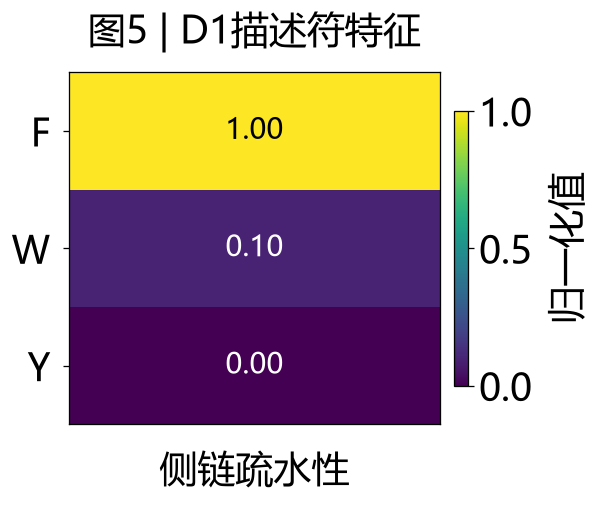

图已保存： notebook_demo_output\05_stage2_D1_descriptor_heatmap.png


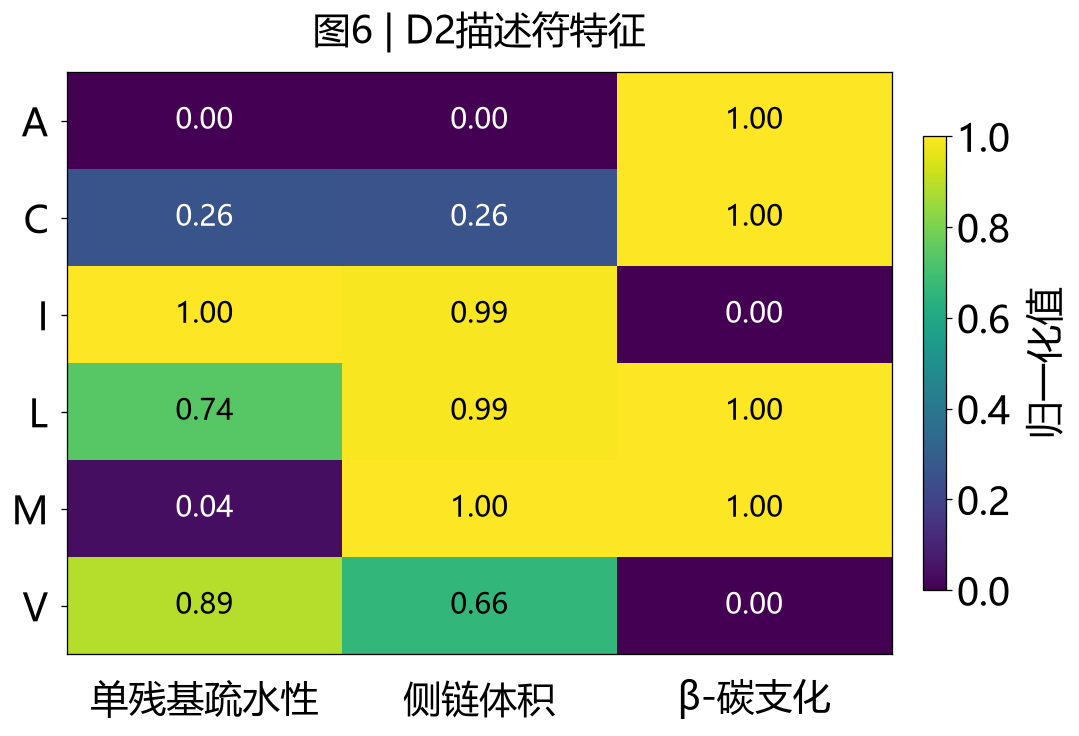

图已保存： notebook_demo_output\06_stage2_D2_descriptor_heatmap.png


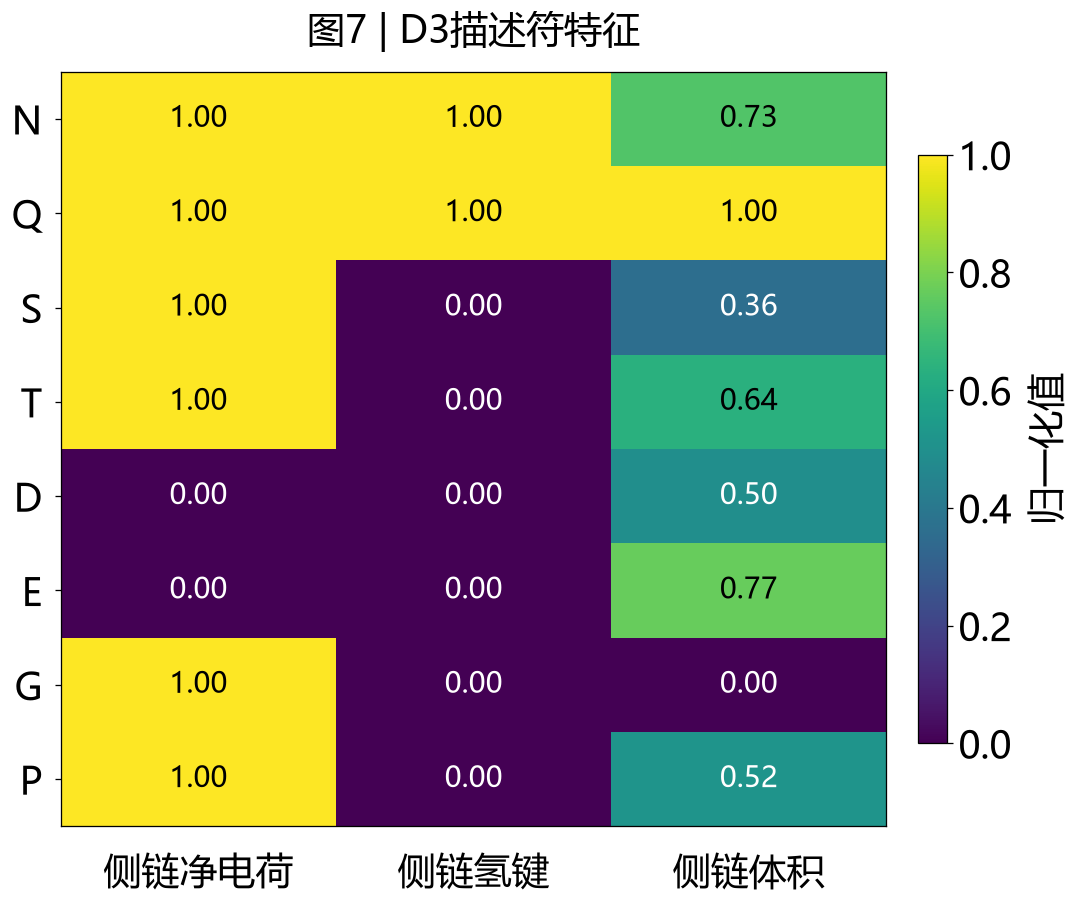

图已保存： notebook_demo_output\07_stage2_D3_descriptor_heatmap.png


In [33]:


def descriptor_heatmap(did, num):
    p = problems[did]
    norm = minmax_by_column(p['matrix'])
    viz = np.where(p['types'] == 1, norm, 1 - norm)

    # 字号统一管理
    TITLE_SIZE = 24     # 图片顶部标题
    CELL_SIZE = 18      # 热图内部数字（保持不变）
    YLABEL_SIZE = 24    # 纵坐标：F、W、Y等
    XLABEL_SIZE = 24    # 横坐标：疏水性、侧链体积等
    CBAR_SIZE = 24      # 右侧颜色条：标签及刻度

    # 不同域采用不同图片尺寸
    fig_sizes = {
        'D1': (5.5, 4.5),
        'D2': (9.5, 6.5),
        'D3': (9.5, 8.0)
    }

    fig, ax = plt.subplots(figsize=fig_sizes[did])

    im = ax.imshow(
        viz,
        cmap='viridis',
        vmin=0,
        vmax=1,
        aspect='auto'
    )

    # 指标名称：中文、分行显示
    label_map = {
        'side-chain hydrophobicity': '侧链疏水性',
        'single-residue hydrophobicity': '单残基疏水性',
        'side-chain volume': '侧链体积',
        'beta-branching': 'β-碳支化',
        'net side-chain charge at ph 7.4': '侧链净电荷',
        'side-chain amide presence': '侧链氢键'
    }

    original_labels = list(p['criteria'].indicator_name)

    display_labels = [
        label_map.get(str(x).strip().lower(), str(x))
        for x in original_labels
    ]

    # 纵坐标
    ax.set_yticks(
        np.arange(len(p['candidates'])),
        p['candidates']
    )

    ax.tick_params(
        axis='y',
        labelsize=YLABEL_SIZE,
        pad=8
    )

    # 横坐标：两行、居中、不旋转
    ax.set_xticks(
        np.arange(len(display_labels)),
        display_labels
    )

    ax.tick_params(
        axis='x',
        labelsize=XLABEL_SIZE,
        pad=12,
        length=0
    )

    for label in ax.get_xticklabels():
        label.set_rotation(0)
        label.set_ha('center')
        label.set_multialignment('center')
        label.set_linespacing(1.25)

    # 热图内部数值
    for i in range(viz.shape[0]):
        for j in range(viz.shape[1]):
            ax.text(
                j, i,
                f'{viz[i, j]:.2f}',
                ha='center',
                va='center',
                fontsize=CELL_SIZE,
                color='black' if viz[i, j] >= 0.55 else 'white'
            )

    # 颜色条
    cbar = fig.colorbar(
        im,
        ax=ax,
        shrink=0.78,
        pad=0.035,
        fraction=0.045
    )

    cbar.set_label(
        '归一化值',
        fontsize=CBAR_SIZE,
        labelpad=10
    )

    cbar.ax.tick_params(labelsize=CBAR_SIZE)

    # 标题
    ax.set_title(
        f'图{num} | {did}描述符特征',
        fontsize=TITLE_SIZE,
        pad=18
    )

    plt.tight_layout()

    savefig(
        f'{num:02d}_stage2_{did}_descriptor_heatmap.png'
    )


# 生成三张图
descriptor_heatmap('D1', 5)
descriptor_heatmap('D2', 6)
descriptor_heatmap('D3', 7)



## 2.4 多准则评分方法与数学原理

**D1：预注册单一疏水指标 min-max 排序**。收益型指标 $x_i$ 的得分

$$s_i=\frac{x_i-\min_k x_k}{\max_k x_k-\min_k x_k}\in[0,1].$$

以芳香域的 Kyte–Doolittle 疏水性为例，数值为 F=2.8、W=−0.9、Y=−1.3，因此 F=1，W≈0.09756，Y=0。**这里的 1.00 是相对归一化，不代表真实材料性能达到了 100%。**

**D2/D3：等权 TOPSIS（与原项目 `pymcdm` 的 min-max 归一化口径一致）**。对每个指标先归一化：

$$r_{ij}=\frac{x_{ij}-\min_i x_{ij}}{\max_i x_{ij}-\min_i x_{ij}},\qquad v_{ij}=w_jr_{ij},\qquad w_j=1/p.$$

这里 $p=3$ 是域内指标数；D3 的电荷指标首先变为 $|q_i|$，β 支化维持 0/1，然后以成本型方向进入 TOPSIS。定义理想最好/最差点（收益型取最大/最小，成本型反之）：

$$A_j^+=\begin{cases}\max_i v_{ij}&\text{收益型}\\\min_i v_{ij}&\text{成本型}\end{cases},\qquad
A_j^-=\begin{cases}\min_i v_{ij}&\text{收益型}\\\max_i v_{ij}&\text{成本型}\end{cases}.$$

$$D_i^+=\sqrt{\sum_j(v_{ij}-A_j^+)^2},\quad D_i^-=\sqrt{\sum_j(v_{ij}-A_j^-)^2},\quad
C_i=\frac{D_i^-}{D_i^++D_i^-}.$$

**$C_i$ 越大表示越靠近该域的理想指标组合，依然不是免疫疗效预测概率。** 以下依次计算归一化矩阵、理想解距离、相对贴近度及候选名次，并与项目保存结果进行数值核验。

In [21]:
def topsis_detail(matrix,types,weights=None):
    x=np.asarray(matrix,dtype=float); t=np.asarray(types,dtype=int)
    n=x.shape[1]
    w=np.ones(n)/n if weights is None else np.asarray(weights,dtype=float)
    w=w/w.sum()
    r=minmax_by_column(x)
    v=r*w[None,:]
    plus=np.where(t==1, v.max(axis=0),v.min(axis=0))
    minus=np.where(t==1, v.min(axis=0),v.max(axis=0))
    dplus=np.sqrt(((v-plus)**2).sum(axis=1))
    dminus=np.sqrt(((v-minus)**2).sum(axis=1))
    pref=dminus/(dplus+dminus)
    return {'norm':r,'weighted':v,'ideal':plus,'anti_ideal':minus,'dplus':dplus,'dminus':dminus,'score':pref}

def borda_detail(matrix, types):
    """按每个指标的收益/成本方向计算 Borda 名次；避免写入 Pandas 的只读 NumPy 视图。"""
    x = np.asarray(matrix, dtype=float)
    directions = np.asarray(types, dtype=int)
    assert x.ndim == 2 and x.shape[1] == len(directions)
    # 对每个指标单独生成新数组，不修改 DataFrame/Series.to_numpy 返回的共享视图
    cols = [pd.Series(x[:, j]).rank(ascending=(directions[j] != 1), method='average')
            .to_numpy(dtype=float, copy=True)
            for j in range(x.shape[1])]
    ranks = np.column_stack(cols)
    return ranks, ranks.sum(axis=1)

computed={}
for did,p in problems.items():
    if did=='D1':
        scores=minmax_by_column(p['matrix']).ravel()
        detail=None
    else:
        detail=topsis_detail(p['matrix'],p['types'])
        scores=detail['score']
    rank=pd.Series(scores).rank(ascending=False,method='min').astype(int).to_numpy()
    if did!='D1':
        borda_ranks,borda_sum=borda_detail(p['matrix'],p['types'])
    else:borda_ranks=None;borda_sum=None
    df=pd.DataFrame({'domain_id':did,'candidate':p['candidates'],'candidate_name_zh':p['labels'],
                     'primary_score':scores,'primary_rank':rank})
    if borda_sum is not None:
        df['borda_rank_sum']=borda_sum
        df['borda_rank']=pd.Series(borda_sum).rank(ascending=True,method='min').astype(int).to_numpy()
    computed[did]=dict(df=df,detail=detail,borda=borda_ranks)
    print('\n',did,'| 实际使用:', '单指标归一化' if did=='D1' else 'TOPSIS')
    display(df.sort_values('primary_rank').round(5))


 D1 | 实际使用: 单指标归一化


,domain_id,candidate,candidate_name_zh,primary_score,primary_rank
0,D1,F,苯丙氨酸,1.00000,1
1,D1,W,色氨酸,0.09756,2
2,D1,Y,酪氨酸,0.00000,3



 D2 | 实际使用: TOPSIS


,domain_id,candidate,candidate_name_zh,primary_score,primary_rank,borda_rank_sum,borda_rank
3,D2,L,亮氨酸,0.85979,1,8.0,1
4,D2,M,甲硫氨酸,0.59500,2,8.5,2
2,D2,I,异亮氨酸,0.58468,3,9.0,3
5,D2,V,缬氨酸,0.51053,4,11.5,4
1,D2,C,半胱氨酸,0.50358,5,11.5,4
0,D2,A,丙氨酸,0.41421,6,14.5,6



 D3 | 实际使用: TOPSIS


,domain_id,candidate,candidate_name_zh,primary_score,primary_rank,borda_rank_sum,borda_rank
1,D3,Q,谷氨酰胺,1.00000,1,6.0,1
0,D3,N,天冬酰胺,0.85366,2,8.0,2
3,D3,T,苏氨酸,0.52682,3,13.0,3
7,D3,P,脯氨酸,0.50384,4,14.0,4
2,D3,S,丝氨酸,0.47294,5,16.0,6
6,D3,G,甘氨酸,0.41421,6,17.0,7
5,D3,E,谷氨酸,0.34906,7,14.5,5
4,D3,D,天冬氨酸,0.24819,8,19.5,8


### TOPSIS 距离、综合得分及 Borda 对照

对 D2、D3 的候选逐一列出到正理想解的距离 $D_i^+$、到负理想解的距离 $D_i^-$ 及相对贴近度 $C_i$。另采用 Borda 排名作非参数对照：分别按各指标的收益/成本方向确定候选名次，再求取秩和；秩和越小表示域内综合次序越靠前。

In [22]:
for did in ['D2','D3']:
    p=problems[did];z=computed[did]['detail']; B=computed[did]
    explanation=pd.DataFrame({'氨基酸':p['labels'],'D+：距最好':z['dplus'],
                              'D−：距最差':z['dminus'],'TOPSIS得分':z['score'],
                              'Borda秩和':B['df']['borda_rank_sum']})
    print('\n',did,'每个指标等权',list(np.round(np.ones(len(p['types']))/len(p['types']),3)))
    print('最优理想点（加权后）：',np.round(z['ideal'],4),'最差理想点：',np.round(z['anti_ideal'],4))
    display(explanation.sort_values('TOPSIS得分',ascending=False).round(5))


 D2 每个指标等权 [np.float64(0.333), np.float64(0.333), np.float64(0.333)]
最优理想点（加权后）： [0.3333 0.3333 0.    ] 最差理想点： [0.     0.     0.3333]


,氨基酸,D+：距最好,D−：距最差,TOPSIS得分,Borda秩和
3,亮氨酸,0.08647,0.53028,0.85979,8.0
4,甲硫氨酸,0.32099,0.47157,0.59500,8.5
2,异亮氨酸,0.33335,0.46929,0.58468,9.0
5,缬氨酸,0.35395,0.36917,0.51053,11.5
1,半胱氨酸,0.34978,0.35483,0.50358,11.5
0,丙氨酸,0.47140,0.33333,0.41421,14.5



 D3 每个指标等权 [np.float64(0.333), np.float64(0.333), np.float64(0.333)]
最优理想点（加权后）： [0.     0.3333 0.3333] 最差理想点： [0.3333 0.     0.    ]


,氨基酸,D+：距最好,D−：距最差,TOPSIS得分,Borda秩和
1,谷氨酰胺,0.00000,0.57735,1.00000,6.0
0,天冬酰胺,0.09087,0.53010,0.85366,8.0
3,苏氨酸,0.35476,0.39498,0.52682,13.0
7,脯氨酸,0.36986,0.37558,0.50384,14.0
2,丝氨酸,0.39520,0.35462,0.47294,16.0
6,甘氨酸,0.47140,0.33333,0.41421,17.0
5,谷氨酸,0.47757,0.25609,0.34906,14.5
4,天冬氨酸,0.50048,0.16522,0.24819,19.5


### 全部候选排名及计算一致性核验

对三个域共 17 种候选氨基酸逐项核对得分和名次，同时核对 D2、D3 的 Borda 秩和。利用逐元素数值校验检验重新计算结果与项目保存的正式结果是否一致。

In [23]:
official_rank=csv('results/stage2_all_rankings.csv')
for did,v in computed.items():
    obs=v['df'].set_index('candidate').sort_index()
    ref=official_rank[official_rank.domain_id==did].set_index('candidate').sort_index()
    np.testing.assert_allclose(obs.primary_score.to_numpy(),ref.primary_score.to_numpy(),atol=1e-12,rtol=0)
    np.testing.assert_array_equal(obs.primary_rank.to_numpy(),ref.primary_rank.to_numpy())
    if did!='D1':
        np.testing.assert_allclose(obs.borda_rank_sum.to_numpy(),ref.borda_rank_sum.to_numpy(),atol=1e-12,rtol=0)
    print(did,': 逐候选得分、排名与正式结果一致 ✅')
print('三域17种候选全部通过数值回归检查。')

D1 : 逐候选得分、排名与正式结果一致 ✅
D2 : 逐候选得分、排名与正式结果一致 ✅
D3 : 逐候选得分、排名与正式结果一致 ✅
三域17种候选全部通过数值回归检查。


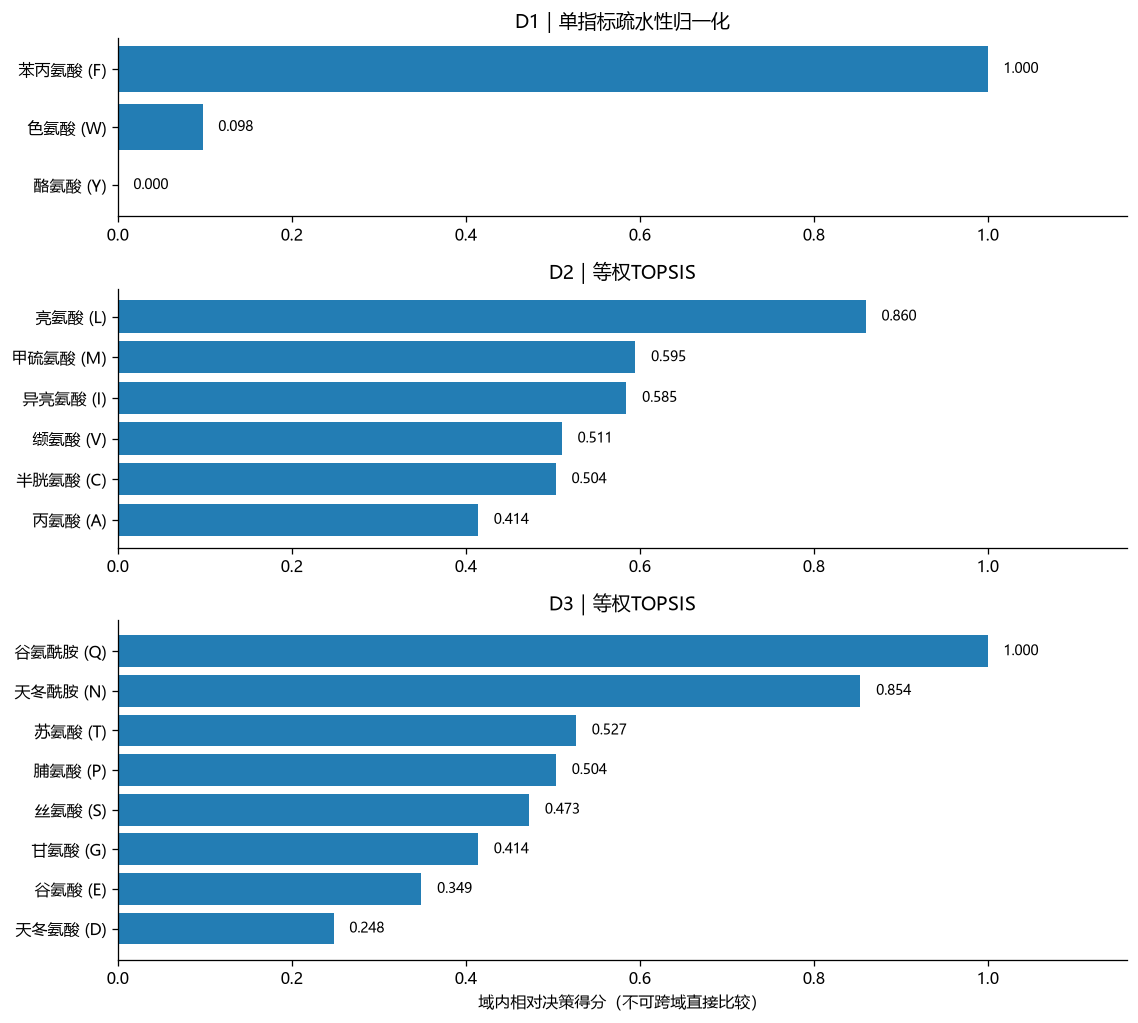

图已保存： notebook_demo_output\08_stage2_within_domain_rankings.png


In [24]:
fig,axes=plt.subplots(3,1,figsize=(10,9),gridspec_kw={'height_ratios':[1.0,1.45,1.9]})
for ax,(did,v) in zip(axes,computed.items()):
    d=v['df'].sort_values('primary_score',ascending=True)
    ax.barh(d['candidate_name_zh']+' ('+d['candidate']+')',d['primary_score'],color='#237db4')
    ax.set_xlim(0,1.16)
    for i,score in enumerate(d.primary_score):ax.text(score+.018,i,f'{score:.3f}',va='center',fontsize=9)
    ax.set_title(did+'｜'+('单指标疏水性归一化' if did=='D1' else '等权TOPSIS'))
    ax.spines[['top','right']].set_visible(False)
axes[-1].set_xlabel('域内相对决策得分（不可跨域直接比较）')
fig.tight_layout()
savefig('08_stage2_within_domain_rankings.png')

## 2.5 多准则排名的稳健性分析

分别开展三类稳健性检验，以评价候选首位结果对评分规则和指标设置的敏感程度：

1. **Borda 排名对照**：采用不同的指标名次汇总方法，比较各域首位候选是否保持一致。
2. **逐项指标消融**：每次移除一个评价指标后重新排序，统计原首位候选的保持比例。
3. **指标权重扰动**：逐项将权重乘以 $0.8$ 或 $1.2$ 并重新归一化；每个域的 3 项指标形成 6 组扰动方案。

结果显示，D2 在指标消融下的首位保持比例为 $1/3$，D3 为 $2/3$，说明部分指标的删除会改变首位候选。权重扰动与指标消融考察的是不同类型的敏感性，应分别报告，不能合并为所谓的“预测准确率”。

In [25]:
def get_winner_for_matrix(x,t):
    if x.shape[1]==1:
        raw=x[:,0]
        return int(np.argmax(raw) if t[0]==1 else np.argmin(raw))
    return int(np.argmax(topsis_detail(x,t)['score']))

ablations=[]; perturb=[]; summaries=[]
for did in ['D2','D3']:
    p=problems[did];x=p['matrix'];t=p['types'];aa=p['candidates']
    baseline=aa[int(np.argmax(computed[did]['df']['primary_score'].to_numpy()))]
    branks,brsum=borda_detail(x,t);borda_winner=aa[int(np.argmin(brsum))]
    for j,ind in enumerate(p['criteria'].indicator_id):
        keep=[k for k in range(x.shape[1]) if k!=j]
        win=aa[get_winner_for_matrix(x[:,keep],t[keep])]
        ablations.append({'domain_id':did,'指标':ind,'删掉后的赢家':win,'原赢家':baseline,'是否保持':win==baseline})
    for j,ind in enumerate(p['criteria'].indicator_id):
        for direction,factor in [('down',.8),('up',1.2)]:
            w=np.ones(x.shape[1])/x.shape[1]
            w[j]*=factor;w/=w.sum()
            win=aa[int(np.argmax(topsis_detail(x,t,w)['score']))]
            perturb.append({'domain_id':did,'指标':ind,'调整':direction,'归一权重':'|'.join(f'{n:.8f}' for n in w),
                            '新赢家':win,'原赢家':baseline,'是否保持':win==baseline})
    summaries.append({'domain_id':did,'Borda一致':float(borda_winner==baseline),
                      '指标消融稳定':sum(r['是否保持'] for r in ablations if r['domain_id']==did)/x.shape[1],
                      '权重扰动稳定':sum(r['是否保持'] for r in perturb if r['domain_id']==did)/(2*x.shape[1])})
abl=pd.DataFrame(ablations); per=pd.DataFrame(perturb); robust=pd.DataFrame(summaries)
display(robust)
print('删掉哪项指标，赢家会变化：')
display(abl)
print('±20%权重扰动明细：')
display(per)
# 与正式归档逐条校验，失败意味着Notebook算法与历史分析口径不一致
ab_ref=csv('results/criterion_ablation.csv')
p_ref=csv('results/weight_perturbation.csv')
for row in abl.itertuples():
    chk=ab_ref[(ab_ref.domain_id==row.domain_id)&(ab_ref.omitted_indicator_id==row.指标)]
    assert len(chk)==1 and chk.new_winner.iloc[0]==row.删掉后的赢家
for row in per.itertuples():
    chk=p_ref[(p_ref.domain_id==row.domain_id)&(p_ref.perturbed_indicator_id==row.指标)&(p_ref.perturbation==row.调整)]
    assert len(chk)==1 and chk.new_winner.iloc[0]==row.新赢家
print('消融与权重扰动的全部赢家同正式记录一致 ✅')

,domain_id,Borda一致,指标消融稳定,权重扰动稳定
0,D2,1.0,0.333333,1.0
1,D3,1.0,0.666667,1.0


删掉哪项指标，赢家会变化：


,domain_id,指标,删掉后的赢家,原赢家,是否保持
0,D2,I1,M,L,False
1,D2,I2,L,L,True
2,D2,I3,I,L,False
3,D3,I1,Q,Q,True
4,D3,I2,Q,Q,True
5,D3,I3,N,Q,False


±20%权重扰动明细：


,domain_id,指标,调整,归一权重,新赢家,原赢家,是否保持
0,D2,I1,down,0.28571429|0.35714286|0.35714286,L,L,True
1,D2,I1,up,0.37500000|0.31250000|0.31250000,L,L,True
2,D2,I2,down,0.35714286|0.28571429|0.35714286,L,L,True
3,D2,I2,up,0.31250000|0.37500000|0.31250000,L,L,True
4,D2,I3,down,0.35714286|0.35714286|0.28571429,L,L,True
5,D2,I3,up,0.31250000|0.31250000|0.37500000,L,L,True
6,D3,I1,down,0.28571429|0.35714286|0.35714286,Q,Q,True
7,D3,I1,up,0.37500000|0.31250000|0.31250000,Q,Q,True
8,D3,I2,down,0.35714286|0.28571429|0.35714286,Q,Q,True
9,D3,I2,up,0.31250000|0.37500000|0.31250000,Q,Q,True


消融与权重扰动的全部赢家同正式记录一致 ✅


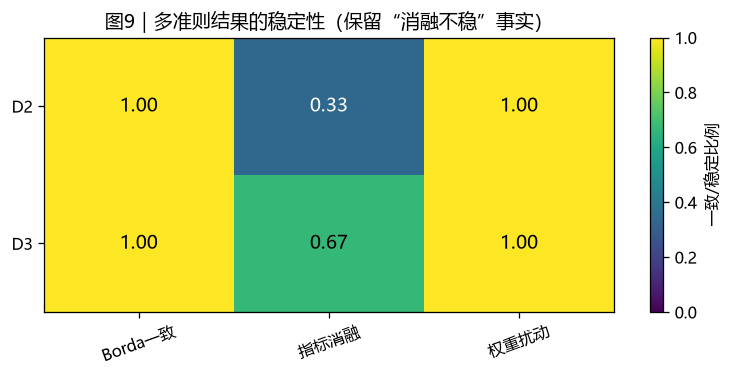

图已保存： notebook_demo_output\09_stage2_D2_D3_robustness.png


In [26]:
arr=robust[['Borda一致','指标消融稳定','权重扰动稳定']].to_numpy()
fig,ax=plt.subplots(figsize=(8,3.1));im=ax.imshow(arr,cmap='viridis',vmin=0,vmax=1,aspect='auto')
ax.set_yticks([0,1],['D2','D3']);ax.set_xticks([0,1,2],['Borda一致','指标消融','权重扰动'],rotation=20)
for i in range(2):
 for j in range(3):ax.text(j,i,f'{arr[i,j]:.2f}',ha='center',va='center',fontsize=12,color='black' if arr[i,j]>.6 else 'white')
ax.set_title('图9｜多准则结果的稳定性（保留“消融不稳”事实）')
fig.colorbar(im,ax=ax,label='一致/稳定比例')
savefig('09_stage2_D2_D3_robustness.png')

## 2.6 芳香疏水域的跨标度敏感性分析

由于 D1 采用单一疏水性指标，对 42 套公开疏水性标度分别比较苯丙氨酸（F）、色氨酸（W）和酪氨酸（Y）的域内排名。结果为 F 在 26 套标度中位居首位，W 在 15 套中位居首位，Y 在 1 套中位居首位。该分析用于评价单一指标选择对排序的影响：F 获得较多标度支持，但并非在所有标度中均排名第一。

被审计标度数： 42


,候选,胜出标度数,比例
0,苯丙氨酸 F,26,0.6190
1,色氨酸 W,15,0.3571
2,酪氨酸 Y,1,0.0238


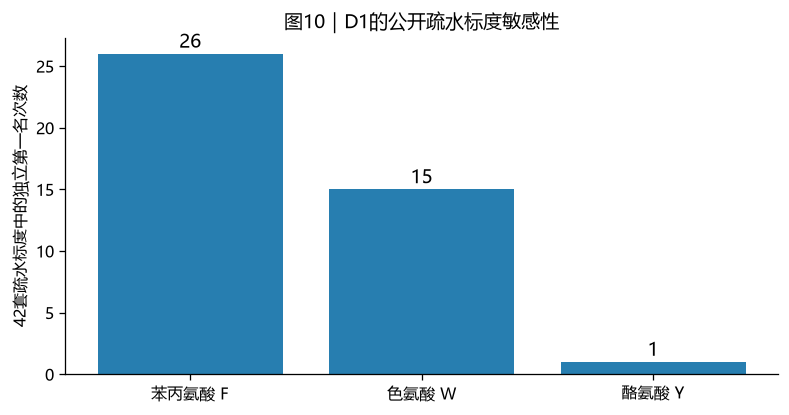

图已保存： notebook_demo_output\10_stage2_D1_hydropathy_sensitivity.png


In [27]:
scales=csv('data/stage2/frozen/d1_hydropathy_audit/hydropathy_scale_results.csv')
counts=scales['winner'].value_counts().reindex(['F','W','Y'],fill_value=0)
assert len(scales)==42
assert counts.to_dict()=={'F':26,'W':15,'Y':1}
print('被审计标度数：',len(scales))
display(pd.DataFrame({'候选':['苯丙氨酸 F','色氨酸 W','酪氨酸 Y'],
                      '胜出标度数':counts.values,'比例':(counts/len(scales)).values}).round(4))
fig,ax=plt.subplots(figsize=(8,3.8))
bars=ax.bar(['苯丙氨酸 F','色氨酸 W','酪氨酸 Y'],counts.values,color='#277eb0')
for b,v in zip(bars,counts):ax.text(b.get_x()+b.get_width()/2,v+.5,str(v),ha='center',fontsize=12)
ax.set_ylabel('42套疏水标度中的独立第一名次数');ax.set_title('图10｜D1的公开疏水标度敏感性')
ax.spines[['top','right']].set_visible(False)
savefig('10_stage2_D1_hydropathy_sensitivity.png')

# 筛选结果 · 优先实验候选汇总

依据 Stage 1 的阳离子功能模块选择和 Stage 2 的域内排序结果，分别得到三种代表性候选第二嵌段：**苯丙氨酸（F）、亮氨酸（L）和谷氨酰胺（Q）**。这些氨基酸可与 D-赖氨酸组合形成待验证的二元聚氨基酸材料；具体嵌段长度与聚合结构需要在后续合成及材料表征中进一步确定。

各机制域的指标种类与归一化参照不同，因此三个域的得分**不用于跨域比较优劣**。本阶段输出的是实验候选优先级，而非对自组装、细胞摄取或免疫激活结果的实测结论。

In [28]:
final=csv('results/results.csv')
new=[]
for did,v in computed.items():
    top=v['df'].sort_values(['primary_rank','candidate']).iloc[0]
    row=final[final['X_block']==top['candidate']]
    assert len(row)==1,(did,top['candidate'])
    new.append({'域':did,'代表性氨基酸':top['candidate_name_zh'],'X':top['candidate'],
                '域内相对得分':round(float(top['primary_score']),4),
                '候选材料结构':str(row.iloc[0]['structure_or_composition'])})
final_view=pd.DataFrame(new)
display(final_view)
assert final_view['X'].tolist()==['F','L','Q']
final_view.to_csv(OUTPUT/'computed_final_candidates.csv',index=False,encoding='utf-8-sig')
pd.concat([v['df'] for v in computed.values()],ignore_index=True).to_csv(OUTPUT/'computed_stage2_rankings.csv',index=False,encoding='utf-8-sig')
print('✅ 与正式候选一致。计算表及10张生成图保存在 notebook_demo_output/。')

,域,代表性氨基酸,X,域内相对得分,候选材料结构
0,D1,苯丙氨酸,F,1.0000,C6-F_m-(D-Lys)_n
1,D2,亮氨酸,L,0.8598,C6-L_m-(D-Lys)_n
2,D3,谷氨酰胺,Q,1.0000,C6-Q_m-(D-Lys)_n


✅ 与正式候选一致。计算表及10张生成图保存在 notebook_demo_output/。


## 3.1 数据来源、计算记录与方法适用范围

本研究保留了文献检索、指标映射、决策矩阵和排序结果之间的可追溯记录：

- **检索策略与文献记录**：`data/stage1/literature/query_summary.csv`、`retrieved_metadata.csv`。
- **相关性排序与文献证据**：`data/stage1/medcpt/`、`data/stage1/rag/contextual_evidence.csv`，并区分数据库检索摘要与证据整理陈述。
- **阳离子模块及手性选择依据**：`data/stage1/decisions/`；模型证据综合调用记录：`provenance/stage1/pairwise_calls/`。
- **人工机制分域**：`data/stage2/frozen/discovery/domain_taxonomy.json`。
- **理化指标选择及证据映射**：`data/stage2/frozen/discovery/`、`data/stage2/frozen/ranking/criteria_used.csv`。
- **数值计算输入**：`data/stage2/frozen/ranking/decision_matrix_long.csv`。
- **域内排名与稳健性结果**：`results/stage2_all_rankings.csv`、`results/criterion_ablation.csv`、`results/weight_perturbation.csv`。

**适用范围：** 本流程在实验样本有限的条件下，以文献知识、材料化学假设和单残基理化特征支持候选优先级判断；后续仍需通过长链材料合成、组装表征与免疫学实验检验其实际适用性。

In [29]:
expected = [
 '01_stage1_full_evidence_funnel.png','02_stage1_evidence_branch_breakdown.png',
 '03_stage1_candidate_medcpt_heatmap.png','04_stage1_chirality_medcpt_heatmap.png',
 '05_stage2_D1_descriptor_heatmap.png','06_stage2_D2_descriptor_heatmap.png',
 '07_stage2_D3_descriptor_heatmap.png','08_stage2_within_domain_rankings.png',
 '09_stage2_D2_D3_robustness.png','10_stage2_D1_hydropathy_sensitivity.png'
]
missing=[name for name in expected if not (OUTPUT/name).is_file()]
assert not missing, f'缺少自动生成的图：{missing}'
print(f'完整计算及绘图结束：{len(expected)} 张图全部存在于 {OUTPUT}。')


完整计算及绘图结束：10 张图全部存在于 E:\Project\shengmingtiaozhansai\notebook_demo_output。
